# Chapter 5: What the loss cannot see

Checks [chapter 5](../../book/05-the-blind-loss.md). Two random models with the same one-point
marginals have the same expected loss.

- the **flat model** draws one number uniformly from `[-1, 1]` and outputs it at every input;
- the **jagged model** draws a fresh number at every input.

For a label `y` and squared error both average `y² + 1/3`. They do not look alike: the loss of the
flat model swings more from draw to draw. The notebook also checks that a random-phase sine has the
same marginal at every input and frequency, and repeats the **measured** claim that untrained ReLU
networks of different widths start with nearly the same error.

These are measurements. The lemma is in `Marginal.lean`. Run every cell, top to bottom. A failed
check stops the notebook.

In [1]:
from common import *
import pandas as pd

use_style()

generator = torch.Generator().manual_seed(5)
torch.manual_seed(5)          # nn.Linear draws its weights from the global generator

## Flat versus jagged: the same average loss

Checks the chapter's claim that both models have the same expected loss, for squared error
(`y² + 1/3`) and for absolute error (`(1 + y²) / 2`), on any labels in `[-1, 1]`.

In [2]:
def get_losses(model_kind, labels, draw_count, generator):
    """Squared and absolute loss of every draw, averaged over the data points."""
    point_count = len(labels)
    if model_kind == "flat":
        outputs = (torch.rand(draw_count, 1, generator=generator) * 2 - 1).expand(draw_count, point_count)
    else:
        outputs = torch.rand(draw_count, point_count, generator=generator) * 2 - 1
    residual = labels - outputs
    return (residual ** 2).mean(dim=1), residual.abs().mean(dim=1)


label_sets = ([0.0], [0.5], [-1.0], [0.0, 0.5, -0.25, 0.9])
rows = []
for label_set in label_sets:
    labels = torch.tensor(label_set)
    torch.rand(len(label_set), generator=generator)      # data inputs; they do not enter the loss, and keep the draws in order
    row = {"labels": label_set}
    for kind in ("flat", "jagged"):
        squared, absolute = get_losses(kind, labels, 400000, generator)
        row[kind] = {"mean_squared": float(squared.mean()), "std_squared": float(squared.std()),
                     "mean_absolute": float(absolute.mean())}
    row["expected_squared"] = float((labels ** 2).mean() + 1 / 3)
    row["expected_absolute"] = float(((1 + labels ** 2) / 2).mean())
    rows.append(row)

for row in rows:
    close_squared = all(abs(row[kind]["mean_squared"] - row["expected_squared"]) < 4e-3 for kind in ("flat", "jagged"))
    close_absolute = all(abs(row[kind]["mean_absolute"] - row["expected_absolute"]) < 4e-3 for kind in ("flat", "jagged"))
    report(f"labels {row['labels']}: both models average y^2 + 1/3 = {row['expected_squared']:.4f} (squared) "
           f"and (1 + y^2)/2 = {row['expected_absolute']:.4f} (absolute)",
           close_squared and close_absolute,
           f"flat {row['flat']['mean_squared']:.4f}, jagged {row['jagged']['mean_squared']:.4f}")

[PASS] labels [0.0]: both models average y^2 + 1/3 = 0.3333 (squared) and (1 + y^2)/2 = 0.5000 (absolute)  (flat 0.3334, jagged 0.3336)
[PASS] labels [0.5]: both models average y^2 + 1/3 = 0.5833 (squared) and (1 + y^2)/2 = 0.6250 (absolute)  (flat 0.5827, jagged 0.5828)
[PASS] labels [-1.0]: both models average y^2 + 1/3 = 1.3333 (squared) and (1 + y^2)/2 = 1.0000 (absolute)  (flat 1.3352, jagged 1.3324)
[PASS] labels [0.0, 0.5, -0.25, 0.9]: both models average y^2 + 1/3 = 0.6140 (squared) and (1 + y^2)/2 = 0.6403 (absolute)  (flat 0.6150, jagged 0.6146)


## Same average, different draws

Checks that the two models are *not* alike draw by draw. With 100 data points the jagged model
averages 100 independent draws, so its loss settles near the average. The flat model uses one draw
for every point, so its loss does not. The chapter quotes a spread of about 0.30 for the flat model
and 0.07 for the jagged one.

In [3]:
many_labels = torch.linspace(-0.9, 0.9, 100)
spread = {}
for kind in ("flat", "jagged"):
    squared, _ = get_losses(kind, many_labels, 50000, generator)
    spread[kind] = {"mean_squared": float(squared.mean()), "std_squared": float(squared.std())}

report("100 data points: same average, but the flat model's loss swings several times more",
       spread["flat"]["std_squared"] > 3 * spread["jagged"]["std_squared"]
       and abs(spread["flat"]["mean_squared"] - spread["jagged"]["mean_squared"]) < 4e-3,
       f"mean flat {spread['flat']['mean_squared']:.4f}, jagged {spread['jagged']['mean_squared']:.4f}; "
       f"std flat {spread['flat']['std_squared']:.3f}, jagged {spread['jagged']['std_squared']:.3f}")

[PASS] 100 data points: same average, but the flat model's loss swings several times more  (mean flat 0.6068, jagged 0.6092; std flat 0.297, jagged 0.068)


True

## Check yourself, question 1: coin flips

A random model outputs a fair coin flip, +1 or -1, the same at every input. Another flips a fresh
coin at every input. The data is one point with label 0. The chapter answers: the expected squared
error is 1 for both, because every flip squares to 1.

In [4]:
coin_flips = (torch.randint(0, 2, (200000,), generator=generator) * 2 - 1).double()

report("coin flips at +1 or -1, label 0: expected squared error is 1 for both", float((coin_flips ** 2).mean()) == 1.0)

[PASS] coin flips at +1 or -1, label 0: expected squared error is 1 for both


True

## A random-phase sine has one marginal everywhere

Checks the claim of chapter 6 that the output of `amplitude * sin(frequency * input + phase)`, with
the phase uniform round the circle, has the same distribution at every input and every frequency.
The phases are an evenly spaced grid, so the sorted outputs are exact quantiles of the marginal.

In [5]:
amplitude = 0.8
phases = (torch.arange(200000) + 0.5) / 200000 * TWO_PI

sorted_reference = None
largest_gap_overall = 0.0
for frequency in (1.0, 4.0, 16.0, 64.0):
    for input_value in (-0.7, 0.2, 3.1):
        outputs = evaluate_sine(amplitude, frequency, phases, torch.tensor(input_value)).sort().values
        if sorted_reference is None:
            sorted_reference = outputs
        largest_gap_overall = max(largest_gap_overall, float((outputs - sorted_reference).abs().max()))

report("random-phase sine: one-point marginal is the same at every input and frequency",
       largest_gap_overall < 1e-3, f"largest gap between sorted outputs {largest_gap_overall:.1e}")

[PASS] random-phase sine: one-point marginal is the same at every input and frequency  (largest gap between sorted outputs 6.8e-06)


True

## Untrained ReLU networks of five widths (measured, not proved)

The chapter says untrained networks of widths 4 to 1024 start with the same error. With PyTorch's
default initialisation the widths differ a little at small width. The last-layer bias is drawn from
`U(-1/√width, 1/√width)`, whose variance `1 / (3 × width)` adds to the error and shrinks with the
width. Everything else is width-free, so without that term every width should agree. The notebook measures
that directly: each network's error is computed twice on the same draw, once as it is and once with the
last-layer bias set to zero (the output minus the bias). The mean without the bias is also compared with
its exact value `1/3 + 2/27`, the width-free part. The five widths are the same networks and data as
before; the chapter calls this a measurement of a different setup from `scripts/initial_mse.py`
(one input, one hidden layer, PyTorch default initialisation with biases), not a re-run of it.

In [6]:
widths = (4, 16, 64, 256, 1024)
width_rows = []
for width in widths:
    losses, losses_without = [], []
    for _ in range(300):
        first = torch.nn.Linear(1, width)
        second = torch.nn.Linear(width, 1)
        inputs = torch.rand(256, 1, generator=generator) * 2 - 1
        labels = torch.rand(256, 1, generator=generator) * 2 - 1
        with torch.no_grad():
            outputs = second(torch.relu(first(inputs)))
            outputs_without = outputs - second.bias                # the same network with its last bias zeroed
        losses.append(float(((labels - outputs) ** 2).mean()))
        losses_without.append(float(((labels - outputs_without) ** 2).mean()))
    losses = torch.tensor(losses)
    losses_without = torch.tensor(losses_without)
    last_bias_variance = 1 / (3 * width)
    width_rows.append({"width": width, "mean_initial_mse": float(losses.mean()),
                       "last_bias_variance": last_bias_variance,
                       "mean_without_last_bias": float(losses_without.mean()),
                       "standard_error_without": float(losses_without.std() / math.sqrt(len(losses_without)))})

raw = [row["mean_initial_mse"] for row in width_rows]
without_bias = [row["mean_without_last_bias"] for row in width_rows]
raw_spread = (max(raw) - min(raw)) / (sum(raw) / len(raw))

report("untrained ReLU networks, widths 4 to 1024: the raw error falls with width only by the "
       "last-layer bias variance 1/(3 width); without it every width agrees (measured)",
       max(without_bias) - min(without_bias) < 0.03,
       "raw means " + ", ".join(f"{value:.3f}" for value in raw) + f" (spread {raw_spread:.0%}); "
       "last bias zeroed: " + ", ".join(f"{value:.3f}" for value in without_bias))

WIDTH_FREE_MEAN = 1 / 3 + 2 / 27
report("with the last bias zeroed, every width has the width-free mean 1/3 + 2/27 = 0.4074 (within 4 standard errors)",
       all(abs(row["mean_without_last_bias"] - WIDTH_FREE_MEAN) < 4 * row["standard_error_without"] for row in width_rows),
       "differences " + ", ".join(f"{row['mean_without_last_bias'] - WIDTH_FREE_MEAN:+.4f} (s.e. {row['standard_error_without']:.4f})"
                                  for row in width_rows))


[PASS] untrained ReLU networks, widths 4 to 1024: the raw error falls with width only by the last-layer bias variance 1/(3 width); without it every width agrees (measured)  (raw means 0.496, 0.421, 0.407, 0.416, 0.407 (spread 21%); last bias zeroed: 0.402, 0.400, 0.405, 0.415, 0.407)
[PASS] with the last bias zeroed, every width has the width-free mean 1/3 + 2/27 = 0.4074 (within 4 standard errors)  (differences -0.0057 (s.e. 0.0062), -0.0076 (s.e. 0.0050), -0.0024 (s.e. 0.0054), +0.0071 (s.e. 0.0063), -0.0008 (s.e. 0.0052))


True

## Figure: flat versus jagged

Written to `book/figures/05-flat-versus-jagged.png`. Left: four draws of the flat model. Middle:
four draws of the jagged model. Right: the distribution of the output at one input, which is the
same for both.

wrote book/figures/05-flat-versus-jagged.png


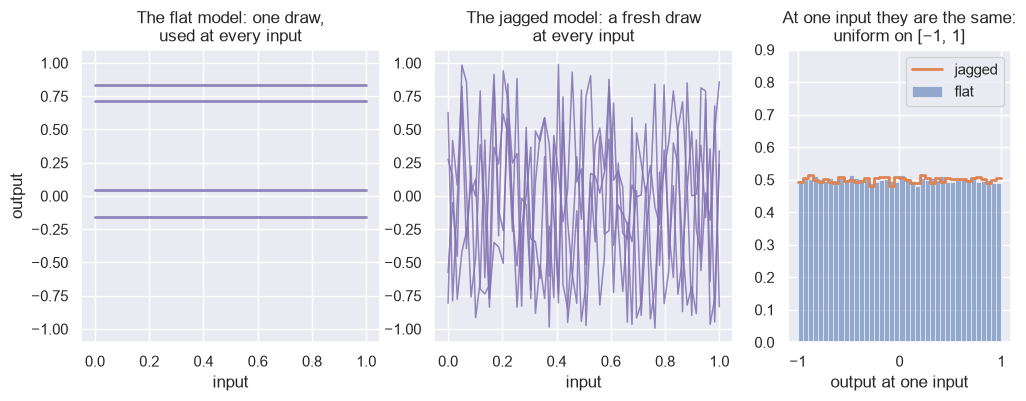

In [7]:
figure_generator = torch.Generator().manual_seed(2)
inputs = torch.linspace(0, 1, 60)

figure, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.2, 1.2, 0.9]})
for draw in range(4):
    level = float(torch.rand(1, generator=figure_generator)) * 2 - 1
    sns.lineplot(x=inputs.numpy(), y=np.full(len(inputs), level), color=MODEL, linewidth=2, alpha=0.85, ax=axes[0])
    sns.lineplot(x=inputs.numpy(), y=(torch.rand(len(inputs), generator=figure_generator) * 2 - 1).numpy(),
                 color=MODEL, linewidth=1.1, alpha=0.85, ax=axes[1])
axes[0].set(title="The flat model: one draw,\nused at every input", ylabel="output", ylim=(-1.1, 1.1), xlabel="input")
axes[1].set(title="The jagged model: a fresh draw\nat every input", ylim=(-1.1, 1.1), xlabel="input")

flat_outputs = (torch.rand(200000, generator=figure_generator) * 2 - 1).numpy()
jagged_outputs = (torch.rand(200000, generator=figure_generator) * 2 - 1).numpy()
sns.histplot(x=flat_outputs, bins=40, binrange=(-1, 1), stat="density", color=NEAREST, alpha=0.55, label="flat", ax=axes[2])
sns.histplot(x=jagged_outputs, bins=40, binrange=(-1, 1), stat="density", element="step", fill=False,
             color=VERTICAL, linewidth=2, label="jagged", ax=axes[2])
axes[2].set(title="At one input they are the same:\nuniform on [−1, 1]", xlabel="output at one input", ylabel="", ylim=(0, 0.9))
axes[2].legend(loc="upper right")
save_figure(figure, "05-flat-versus-jagged")

## Figure: with and without the last-layer bias

Written to `book/figures/05-with-and-without-last-bias.png`. The bars are the numbers computed above.

wrote book/figures/05-with-and-without-last-bias.png


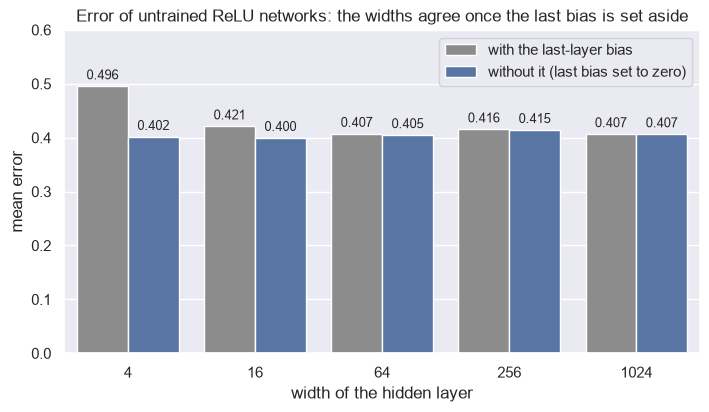

In [8]:
bars = pd.DataFrame(
    [{"width": str(row["width"]), "kind": kind, "mean error": row[key]}
     for row in width_rows
     for kind, key in (("with the last-layer bias", "mean_initial_mse"),
                       ("without it (last bias set to zero)", "mean_without_last_bias"))])

figure, axis = plt.subplots(figsize=(8.2, 4.2))
sns.barplot(data=bars, x="width", y="mean error", hue="kind", palette=[BEFORE, NEAREST], ax=axis)
for container in axis.containers:
    axis.bar_label(container, fmt="%.3f", padding=3, fontsize=9)
axis.set(xlabel="width of the hidden layer", ylabel="mean error", ylim=(0, 0.6),
         title="Error of untrained ReLU networks: the widths agree once the last bias is set aside")
axis.legend(title="", loc="upper right")
save_figure(figure, "05-with-and-without-last-bias")